In [2]:
# Import the Libraries 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf



============= Complete Stock Analyzer =============


 Enter the stock symbol (or 'Quit' to exit): RELIANCE.NS



________________________________
Company : Reliance Industries Limited
 Current Price: 1313.4 INR
 Change: +2.40 (+0.18%)


Enter the start date (yyyy-mm-dd): 2022-01-01
Enter the end date (yyyy-mm-dd): 2026-11-05


[*********************100%***********************]  1 of 1 completed


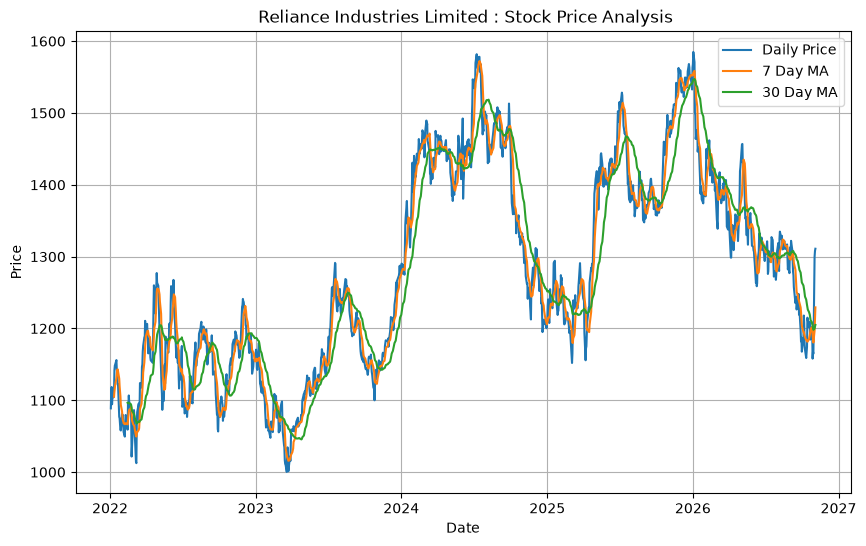

 Enter the stock symbol (or 'Quit' to exit): quit


Exiting Program. Thanks for using.


In [10]:
print("============= Complete Stock Analyzer =============")

while True:
    symbol = input(" Enter the stock symbol (or 'Quit' to exit):").upper()
    
    if symbol == "Quit".upper():
        print("Exiting Program. Thanks for using.")
        break

    try:
        stock = yf.Ticker(symbol)
        info = stock.info 

        name = info.get("longName","N/A")
        price = info.get("currentPrice")
        prev_close = info.get("previousClose")
        currency = info.get("currency","USD")

        print("\n________________________________")
        print(f"Company : {name}")
        print(f" Current Price: {price} {currency}")

        if price and prev_close:
            change = price - prev_close 
            percent = (change/prev_close)*100

            print(f" Change: {change:+.2f} ({percent:+.2f}%)")
            
        

        start_date = input("Enter the start date (yyyy-mm-dd):")
        end_date = input("Enter the end date (yyyy-mm-dd):")

        df = yf.download(symbol,start = start_date, end = end_date, interval="1d")
        df["7_day_MA"] = df ["Close"].rolling(window=7).mean()
        df["30_day_MA"] = df ["Close"].rolling(windows=30).mean()



        # Plot the graph

        plt.figure(figsize=(10,6))
        plt.plot(df["Close"],label = "Daily Price" )
        plt.plot(df["7_day_MA"],label ="7 Day MA")
        plt.plot(df["30_day_MA"],label = "30 Day MA")
        plt.title(f" {name} : Stock Price Analysis")
        plt.xlabel("Date")
        plt.ylabel("Price")
        plt.legend()
        plt.grid(True)
        plt.show()
     


    except Exception as e :
        print("Invalid Symbol or Network Error")

    
